# IBM Telco Customer Churn & Retention Analysis
**Dataset:** User-provided IBM Telco Customer Churn CSV (7,043 rows).  
**Objective:** Profile data quality, compare churn across tenure, contract, payment and pricing segments, identify high-risk service combinations, and estimate churn probabilities.  
**Methodological note:** This is a cross-sectional snapshot. The tenure-group non-churn percentages below are **not** longitudinal retention/survival curves; true survival curves require customer start and cancellation dates. Model probabilities are predictive estimates, not causal effects.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from IPython.display import display
sns.set_theme(style="whitegrid")
source = Path('/mnt/data/telco_customer_churn (1).csv')
if not source.exists():
    source = Path('telco_customer_churn (1).csv')
df = pd.read_csv(source)
print('Shape:', df.shape)
display(df.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data quality and cleaning

In [2]:
print('Duplicate customer IDs:', df.customerID.duplicated().sum())
print('Missing values before conversion:')
display(df.isna().sum().to_frame('null_count').query('null_count > 0'))
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('TotalCharges missing after numeric conversion:', df.TotalCharges.isna().sum())
print('Rows with missing TotalCharges:', df.loc[df.TotalCharges.isna(), ['tenure','MonthlyCharges','Churn']].head(12).to_string(index=False))
# Zero-tenure accounts have blank lifetime charges in this dataset; fill with 0.
assert (df.loc[df.TotalCharges.isna(),'tenure'] == 0).all()
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['ChurnFlag'] = df['Churn'].map({'Yes':1,'No':0})
assert df['ChurnFlag'].notna().all()
assert not df.customerID.duplicated().any()
print('Remaining null cells:', df.isna().sum().sum())

Duplicate customer IDs: 0
Missing values before conversion:


,null_count


TotalCharges missing after numeric conversion: 11
Rows with missing TotalCharges:  tenure  MonthlyCharges Churn
      0           52.55    No
      0           20.25    No
      0           80.85    No
      0           25.75    No
      0           56.05    No
      0           19.85    No
      0           25.35    No
      0           20.00    No
      0           19.70    No
      0           73.35    No
      0           61.90    No
Remaining null cells: 0


## 2. Baseline churn and tenure cohorts

Customers: 7,043 | Churned: 1,869 | Churn rate: 26.54%


,Customers,Churned,ChurnRate,NonChurnShare
TenureCohort,,,,
0–12,2186,1037,47.4%,52.6%
13–24,1024,294,28.7%,71.3%
25–36,832,180,21.6%,78.4%
37–48,762,145,19.0%,81.0%
49–60,832,120,14.4%,85.6%
61–72,1407,93,6.6%,93.4%


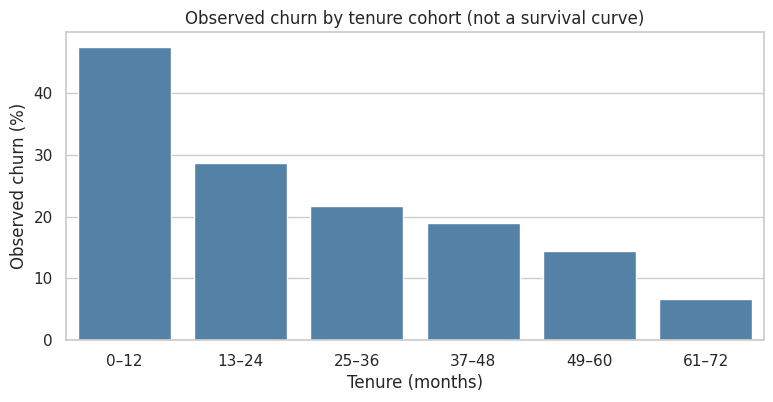

In [3]:
baseline = df.ChurnFlag.mean()
print(f'Customers: {len(df):,} | Churned: {df.ChurnFlag.sum():,} | Churn rate: {baseline:.2%}')
bins = [-1,12,24,36,48,60,72]
labels = ['0–12','13–24','25–36','37–48','49–60','61–72']
df['TenureCohort'] = pd.cut(df.tenure, bins=bins, labels=labels)
cohorts = df.groupby('TenureCohort', observed=True).agg(Customers=('ChurnFlag','size'),Churned=('ChurnFlag','sum'),ChurnRate=('ChurnFlag','mean'))
cohorts['NonChurnShare'] = 1 - cohorts.ChurnRate
display(cohorts.style.format({'ChurnRate':'{:.1%}','NonChurnShare':'{:.1%}'}))
fig, ax=plt.subplots(figsize=(9,4)); sns.barplot(x=cohorts.index.astype(str), y=cohorts.ChurnRate*100,ax=ax,color='steelblue');ax.set(xlabel='Tenure (months)',ylabel='Observed churn (%)',title='Observed churn by tenure cohort (not a survival curve)');plt.show()

## 3. Contract, payment, monthly charges and service-tier segmentation


 Contract


,Customers,Churned,ChurnRate,AvgMonthlyCharge
Contract,,,,
Month-to-month,3875,1655,42.7%,$66.40
One year,1473,166,11.3%,$65.05
Two year,1695,48,2.8%,$60.77



 PaymentMethod


,Customers,Churned,ChurnRate,AvgMonthlyCharge
PaymentMethod,,,,
Electronic check,2365,1071,45.3%,$76.26
Mailed check,1612,308,19.1%,$43.92
Bank transfer (automatic),1544,258,16.7%,$67.19
Credit card (automatic),1522,232,15.2%,$66.51



 InternetService


,Customers,Churned,ChurnRate,AvgMonthlyCharge
InternetService,,,,
Fiber optic,3096,1297,41.9%,$91.50
DSL,2421,459,19.0%,$58.10
No,1526,113,7.4%,$21.08



 TechSupport


,Customers,Churned,ChurnRate,AvgMonthlyCharge
TechSupport,,,,
No,3473,1446,41.6%,$74.59
Yes,2044,310,15.2%,$80.68
No internet service,1526,113,7.4%,$21.08


Monthly charge quartiles:


,Customers,Churned,ChurnRate,AvgMonthlyCharge
ChargeBand,,,,
"(70.35, 89.85]",1757,659,37.5%,$80.33
"(89.85, 118.75]",1758,578,32.9%,$100.90
"(35.5, 70.35]",1766,434,24.6%,$55.73
"(18.249, 35.5]",1762,198,11.2%,$22.23


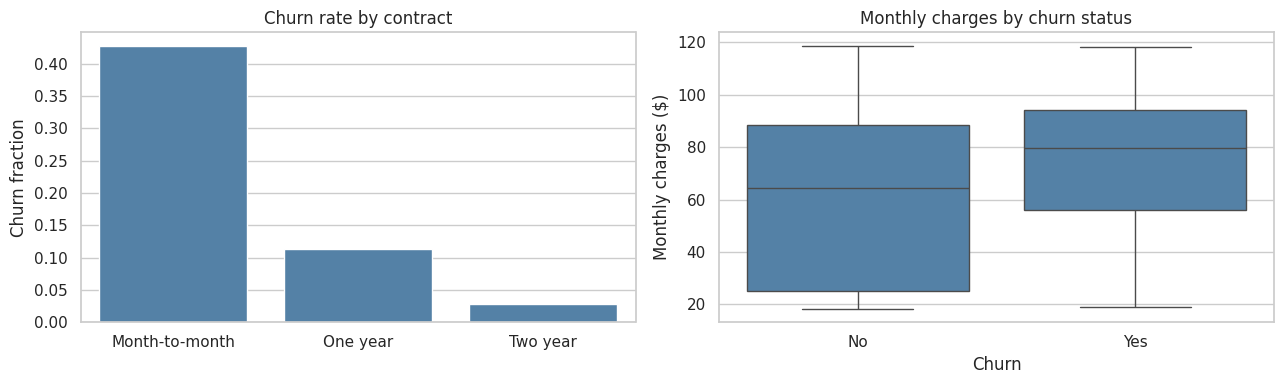

In [4]:
def segment(col):
    out=df.groupby(col,observed=True).agg(Customers=('ChurnFlag','size'),Churned=('ChurnFlag','sum'),ChurnRate=('ChurnFlag','mean'),AvgMonthlyCharge=('MonthlyCharges','mean'))
    return out.sort_values('ChurnRate',ascending=False)
for col in ['Contract','PaymentMethod','InternetService','TechSupport']:
    print('\n',col);display(segment(col).style.format({'ChurnRate':'{:.1%}','AvgMonthlyCharge':'${:,.2f}'}))
df['ChargeBand']=pd.qcut(df.MonthlyCharges,q=4,duplicates='drop')
print('Monthly charge quartiles:');display(segment('ChargeBand').style.format({'ChurnRate':'{:.1%}','AvgMonthlyCharge':'${:,.2f}'}))
fig,axs=plt.subplots(1,2,figsize=(13,4))
sns.barplot(data=df,x='Contract',y='ChurnFlag',errorbar=None,color='steelblue',ax=axs[0]);axs[0].set(title='Churn rate by contract',ylabel='Churn fraction',xlabel='')
sns.boxplot(data=df,x='Churn',y='MonthlyCharges',color='steelblue',ax=axs[1]);axs[1].set(title='Monthly charges by churn status',ylabel='Monthly charges ($)')
plt.tight_layout();plt.show()

## 4. Churn heatmaps and high-risk segment

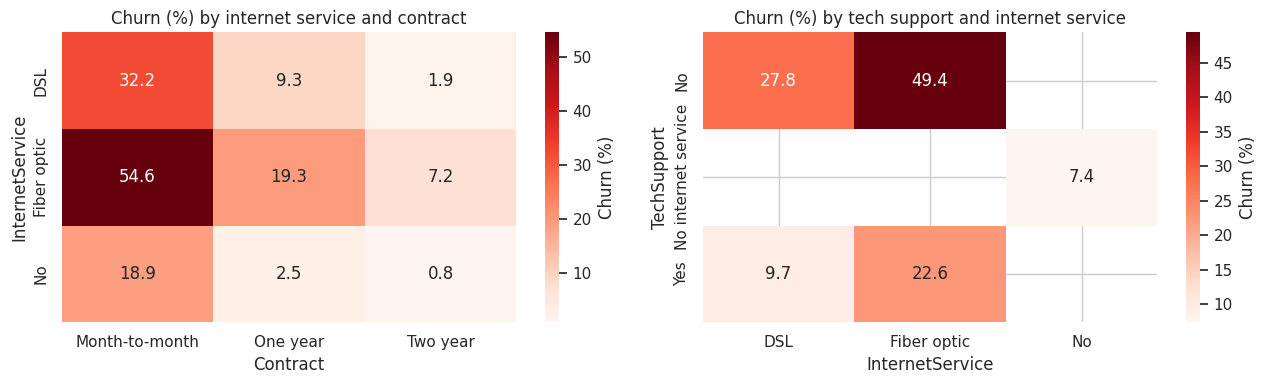

Fiber-optic without tech support: 2,230 customers, churn rate 49.4%
Other customers: 4,813, churn rate 16.0%


In [5]:
heat=df.pivot_table(index='InternetService',columns='Contract',values='ChurnFlag',aggfunc='mean',observed=True)
fig,axs=plt.subplots(1,2,figsize=(13,4))
sns.heatmap(heat*100,annot=True,fmt='.1f',cmap='Reds',ax=axs[0],cbar_kws={'label':'Churn (%)'});axs[0].set_title('Churn (%) by internet service and contract')
heat2=df.pivot_table(index='TechSupport',columns='InternetService',values='ChurnFlag',aggfunc='mean',observed=True)
sns.heatmap(heat2*100,annot=True,fmt='.1f',cmap='Reds',ax=axs[1],cbar_kws={'label':'Churn (%)'});axs[1].set_title('Churn (%) by tech support and internet service')
plt.tight_layout();plt.show()
high_risk=(df.InternetService.eq('Fiber optic') & df.TechSupport.eq('No'))
print(f'Fiber-optic without tech support: {high_risk.sum():,} customers, churn rate {df.loc[high_risk,"ChurnFlag"].mean():.1%}')
print(f'Other customers: {(~high_risk).sum():,}, churn rate {df.loc[~high_risk,"ChurnFlag"].mean():.1%}')

## 5. Churn probability model (out-of-sample logistic regression)
Model is descriptive/predictive, not causal. Holdout performance and probabilities depend on the split and selected variables. Customer ID and TotalCharges are excluded; the latter strongly overlaps with tenure and charges.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score,classification_report,brier_score_loss
features=['tenure','MonthlyCharges','Contract','PaymentMethod','InternetService','TechSupport','OnlineSecurity','PaperlessBilling']
X=df[features]; y=df.ChurnFlag
num=['tenure','MonthlyCharges'];cat=[c for c in features if c not in num]
prep=ColumnTransformer([('num',StandardScaler(),num),('cat',OneHotEncoder(handle_unknown='ignore'),cat)])
model=Pipeline([('prep',prep),('clf',LogisticRegression(max_iter=2000))])
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
model.fit(X_train,y_train)
pred=model.predict_proba(X_test)[:,1]
print(f'Holdout ROC AUC: {roc_auc_score(y_test,pred):.3f}; Brier score: {brier_score_loss(y_test,pred):.3f}')
print(classification_report(y_test,pred>=.5,zero_division=0))
risk=pd.DataFrame({'ActualChurn':y_test.to_numpy(),'PredictedProbability':pred})
risk['RiskDecile']=pd.qcut(risk.PredictedProbability,10,labels=False,duplicates='drop')+1
display(risk.groupby('RiskDecile').agg(Customers=('ActualChurn','size'),ObservedChurn=('ActualChurn','mean'),MeanPredicted=('PredictedProbability','mean')).style.format({'ObservedChurn':'{:.1%}','MeanPredicted':'{:.1%}'}))

Holdout ROC AUC: 0.840; Brier score: 0.139
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1294
           1       0.64      0.52      0.57       467

    accuracy                           0.79      1761
   macro avg       0.74      0.70      0.72      1761
weighted avg       0.78      0.79      0.79      1761



,Customers,ObservedChurn,MeanPredicted
RiskDecile,,,
1,177,1.1%,1.0%
2,176,0.0%,2.6%
3,176,4.5%,5.0%
4,176,11.9%,9.0%
5,176,16.5%,14.7%
6,176,24.4%,22.8%
7,176,36.4%,34.2%
8,176,40.9%,46.1%
9,176,59.1%,59.2%


## 6. Executive findings and recommendations (computed from the uploaded data)

In [7]:
contract=segment('Contract'); payment=segment('PaymentMethod'); internet=segment('InternetService')
first=cohorts.iloc[0];last=cohorts.iloc[-1]
charge=segment('ChargeBand').sort_index()
print(f'1. Baseline: {df.ChurnFlag.sum():,} of {len(df):,} customers churned ({baseline:.1%}). RECOMMENDATION: Track this as the overall churn KPI.')
print(f'2. Tenure: 0–12 month customers churned at {first.ChurnRate:.1%}, versus {last.ChurnRate:.1%} at 61–72 months. RECOMMENDATION: Prioritize onboarding and early lifecycle outreach; cohorts are cross-sectional.')
print(f'3. Contracts: Month-to-month churn {contract.loc["Month-to-month","ChurnRate"]:.1%}, one-year {contract.loc["One year","ChurnRate"]:.1%}, two-year {contract.loc["Two year","ChurnRate"]:.1%}. RECOMMENDATION: Test annual-plan incentives, not assume contract length causes churn.')
worst=payment.index[0];print(f'4. Payment: {worst} has the highest observed churn at {payment.iloc[0].ChurnRate:.1%} (n={payment.iloc[0].Customers:,.0f}). RECOMMENDATION: Investigate billing friction and payment experiences.')
print(f'5. Service risk: Fiber-optic customers without tech support churned at {df.loc[high_risk,"ChurnFlag"].mean():.1%} (n={high_risk.sum():,}) versus {df.loc[~high_risk,"ChurnFlag"].mean():.1%} for others. RECOMMENDATION: Pilot targeted support offers and measure uplift.')
print(f'6. Price: Lowest monthly-charge quartile churn {charge.iloc[0].ChurnRate:.1%} for band {charge.index[0]}, while highest-charge quartile churn {charge.iloc[-1].ChurnRate:.1%} for band {charge.index[-1]}. RECOMMENDATION: Examine price sensitivity within contract and service groups before changing pricing.')
print(f'7. Prediction: Logistic model holdout ROC AUC {roc_auc_score(y_test,pred):.3f}. RECOMMENDATION: Use risk scores to prioritize voluntary retention outreach; monitor calibration, drift, and fairness.')

1. Baseline: 1,869 of 7,043 customers churned (26.5%). RECOMMENDATION: Track this as the overall churn KPI.
2. Tenure: 0–12 month customers churned at 47.4%, versus 6.6% at 61–72 months. RECOMMENDATION: Prioritize onboarding and early lifecycle outreach; cohorts are cross-sectional.
3. Contracts: Month-to-month churn 42.7%, one-year 11.3%, two-year 2.8%. RECOMMENDATION: Test annual-plan incentives, not assume contract length causes churn.
4. Payment: Electronic check has the highest observed churn at 45.3% (n=2,365). RECOMMENDATION: Investigate billing friction and payment experiences.
5. Service risk: Fiber-optic customers without tech support churned at 49.4% (n=2,230) versus 16.0% for others. RECOMMENDATION: Pilot targeted support offers and measure uplift.
6. Price: Lowest monthly-charge quartile churn 11.2% for band (18.249, 35.5], while highest-charge quartile churn 32.9% for band (89.85, 118.75]. RECOMMENDATION: Examine price sensitivity within contract and service groups before

## Interpretation limits
- **Snapshot bias:** The observed churn fraction within a tenure band is not a true retention probability over time. There are no observed start/end dates to construct Kaplan–Meier curves.
- **No causal inference:** Differences by payment method, contract, support, or price can reflect customer mix and selection effects.
- **Predictive probabilities:** These are model-based estimates from a random holdout, not experimentally validated intervention effects.
- **Next step:** Obtain longitudinal billing and cancellation records to calculate actual cohort retention curves and assess targeted interventions.